In [17]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-06


In [18]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
from math_func import *

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


campagnes = ['campagne_r0']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 0.00267s


r0_2


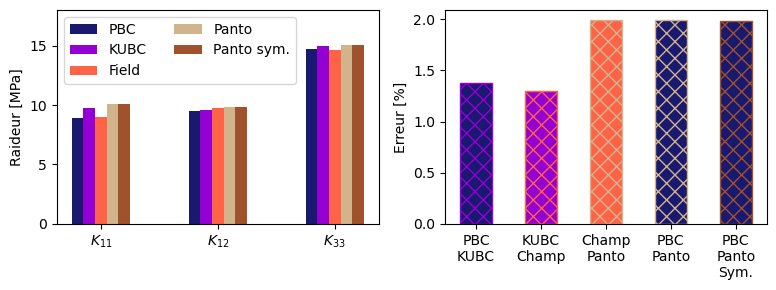

In [19]:
test=data_bulk['r0_2']
print(test.test_id)

plt.figure(figsize=(8,3))
plt.subplot(121)
width=0.1
x=np.linspace(0,2,3)
plt.bar(x-0.2,[test.K_plane_stress_PBC[0][0],test.K_plane_stress_PBC[1][0],test.K_plane_stress_PBC[2][2]],
        width, color='midnightblue', label='PBC')
plt.bar(x-0.1,[test.K_plane_stress_KUBC[0][0],test.K_plane_stress_KUBC[1][0],test.K_plane_stress_KUBC[2][2]],
        width, color='darkviolet', label='KUBC')
plt.bar(x+0.0,[test.K_field_dic[0][0],test.K_field_dic[1][0],test.K_field_dic[2][2]],
        width, color='tomato', label='Field')
plt.bar(x+0.1,[test.K_panto_dic[0][0],test.K_panto_dic[1][0],test.K_panto_dic[2][2]],
        width, color='tan',  label='Panto')
k_sym=get_sym_part(test.K_panto_dic)
plt.bar(x+0.2,[k_sym[0][0],k_sym[1][0],k_sym[2][2]],
        width, color='sienna',  label='Panto sym.')

plt.legend(loc='upper left', ncol=2)
plt.ylabel('Raideur [MPa]')
plt.ylim(top=18)
plt.xticks(range(3), [r'$K_{11}$',r'$K_{12}$',r'$K_{33}$'])



plt.subplot(122)
width=0.5
x=np.linspace(0,4,5)



plt.bar(0,[test.get_error((0,1))],
        width, color='midnightblue',edgecolor='darkviolet', hatch="xx")
plt.bar(1,[test.get_error((1,2))],
        width, color='darkviolet',edgecolor='tomato', hatch="xx")
plt.bar(2,[test.get_error((2,3))],
        width, color='tomato',edgecolor='tan', hatch="xx")
plt.bar(3,[test.get_error((0,3))],
        width, color='midnightblue',edgecolor='tan', hatch="xx")
plt.bar(4,[get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part(test.K_panto_dic))],
        width, color='midnightblue',edgecolor='sienna', hatch="xx")

plt.ylabel('Erreur [%]')
plt.xticks(range(5), ['PBC\nKUBC',
                      'KUBC\nChamp',
                      'Champ\nPanto',
                      'PBC\nPanto','PBC\nPanto\nSym.'])
plt.tight_layout()
plt.savefig('images/err_ro_coef.pdf')

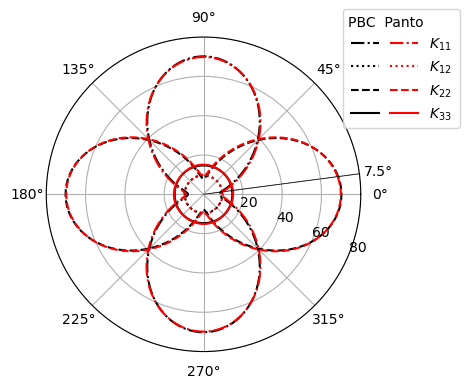

In [20]:



K_0 = np.array(test.K_plane_stress_PBC)

plt.subplots(subplot_kw={'projection': 'polar'})
offset=7.5

K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['k-.', 'k:', 'k--', 'k-']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],label=r'$K_3$')

# * * * * * * * * * *
K_0 = np.array(test.K_panto_dic)
K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
coeff_name=[r'$K_{11}$',r'$K_{12}$',r'$K_{22}$',r'$K_{33}$']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],color='red' ,label=coeff_name[c_i])

# * * * * * * * *
plt.plot([offset/180*pi]*2,[0,80],'k-',lw=0.5)

ax=plt.gca()
ax.set_thetagrids((0,7.5,45,90,135,180,225,270,315),[f'{i}°' for i in [0,7.5,45,90,135,180,225,270,315]])
ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

ax.set_rticks([20,40,60,80])
ax.set_rlabel_position(-22.5)  


l=plt.legend(title='PBC  Panto       ',ncol=2,columnspacing=-1.2,
           loc='center left', bbox_to_anchor=(0.92, 0.9))
plt.ylim((0,80))


for text in l.get_texts()[:4]:
    text.set_color("white")
plt.tight_layout()
plt.savefig('images/r0_polar.pdf')

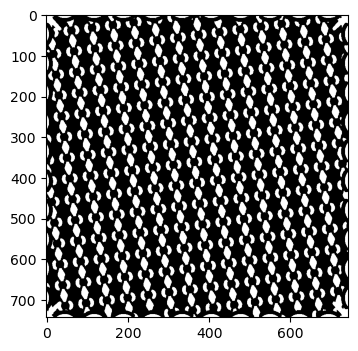

In [21]:
test.show_geo()

In [22]:

# * On décide maintenant de prendre 4 essais à 7.5° et 10°

test_1 = data_bulk['r0_1']
test_2 = data_bulk['r0_2']
test_3 = data_bulk['r0_3']
test_4 = data_bulk['r0_4']
test_list = [test_1,test_2,test_3,test_4]

K_PBC = np.array(test_1.K_plane_stress_PBC)
K_panto_1 = np.array(test_1.K_panto_dic)
K_panto_2 = np.array(test_2.K_panto_dic)
K_panto_3 = np.array(test_3.K_panto_dic)
K_panto_4 = np.array(test_4.K_panto_dic)

# On tourne les matrices qui sont à 10° de -2.5° pour les comparer à 7.5°
K_panto_3 = rotation_voigt(K_panto_3, -2.5*pi/180)
K_panto_4 = rotation_voigt(K_panto_4, -2.5*pi/180)

print('Erreur individuelle test par test')
for t in test_list:
    print(t.get_error((0,3)))


print('Erreur en faisant la moyenne des tests')
k_mean = get_sym_part((K_panto_1+K_panto_2+K_panto_3+K_panto_4) / 4)
mean_err = get_error_custom(K_PBC, k_mean)
print(mean_err)


Erreur individuelle test par test
1.7209759466425725
1.992065896333839
1.89896649332897
2.039457293967272
Erreur en faisant la moyenne des tests
1.8370523814761175
